In [1]:
#pip install plotnine

In [62]:
import pandas as pd
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text, geom_point, geom_histogram, facet_wrap, geom_line
import re
from datetime import datetime

In [63]:
# First, download the metadata CSV file
METADATA = "sequence_metadata/sequence_metadata_07012024.csv"
metadata = pd.read_csv(METADATA, sep = ",")
metadata.head()
# This dataset has H5NX alphainfluenza sequences uploaded to NCBI Virus, collected from North American birds between Jan. 1, 2022 and Jun. 14, 2024

,Accession,Organism_Name,SRA_Accession,Organization,Org_location,Release_Date,Isolate,Species,Molecule_type,Length,...,Segment,Geo_Location,Country,USA,Host,Isolation_Source,Collection_Date,BioSample,BioProject,GenBank_Title
0,PP929863.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2313,...,1,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
1,PP929864.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2315,...,2,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
2,PP929865.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),2207,...,3,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
3,PP929866.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),1729,...,4,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...
4,PP929867.1,Influenza A virus,NaN,"Servicio Nacional de Sanidad, Inocuidad, y Cal...",Mexico,2024-06-23,CPA-01654-24,Alphainfluenzavirus influenzae,ssRNA(-),1539,...,5,"Mexico: EdoMex,texcoco",Mexico,NaN,Gallus gallus,"spleen, abdominal cavity, lung",2024-02-29,NaN,NaN,Influenza A virus (A/Gallus gallus/texcoco/CPA...


In [64]:
# Keep entry only if Collection Date matches YYYY-MM-DD format 
metadata_filtered = metadata[metadata["Collection_Date"].str.match(r"^\d{4}-\d{2}-\d{2}$")]

In [65]:
#metadata_filtered.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_test.csv", sep=",")

In [66]:
# # How to: format a string as a date
# x = "2024-05-01"
# from datetime import datetime 
# date_obj = datetime.strptime(x, '%Y-%m-%d')
# print(date_obj)
# print(type(date_obj))

In [67]:
print(type(metadata_filtered["Collection_Date"]))

<class 'pandas.core.series.Series'>


In [68]:
# This function formats strings in a column as dates (with questionable help from Chat)
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [69]:
# Apply the format_date function to format dates
metadata_filtered["Collection_datetime"] = metadata_filtered["Collection_Date"].apply(format_date)

#Alternative methods (not sure if they work...)

#metadata_filtered["Collection_datetime"] = pd.to_datetime(metadata_filtered["Collection_datetime"], format = '%Y-%m-%d')

#metadata_filtered['Collection_Date'] = pd.to_datetime(metadata_filtered['Collection_Date'], format='%Y-%m-%d')

#metadata_filtered["Collection_datetime"] = metadata_filtered["Collection_Date"].apply(lambda x: datetime.strptime(x, '%Y-%m-%d'))

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/912505714.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [70]:
# Check work to make sure that each object in Collection_datetime is a datetime object
print(type(metadata_filtered["Collection_datetime"].dtype))

<class 'numpy.dtypes.DateTime64DType'>


89


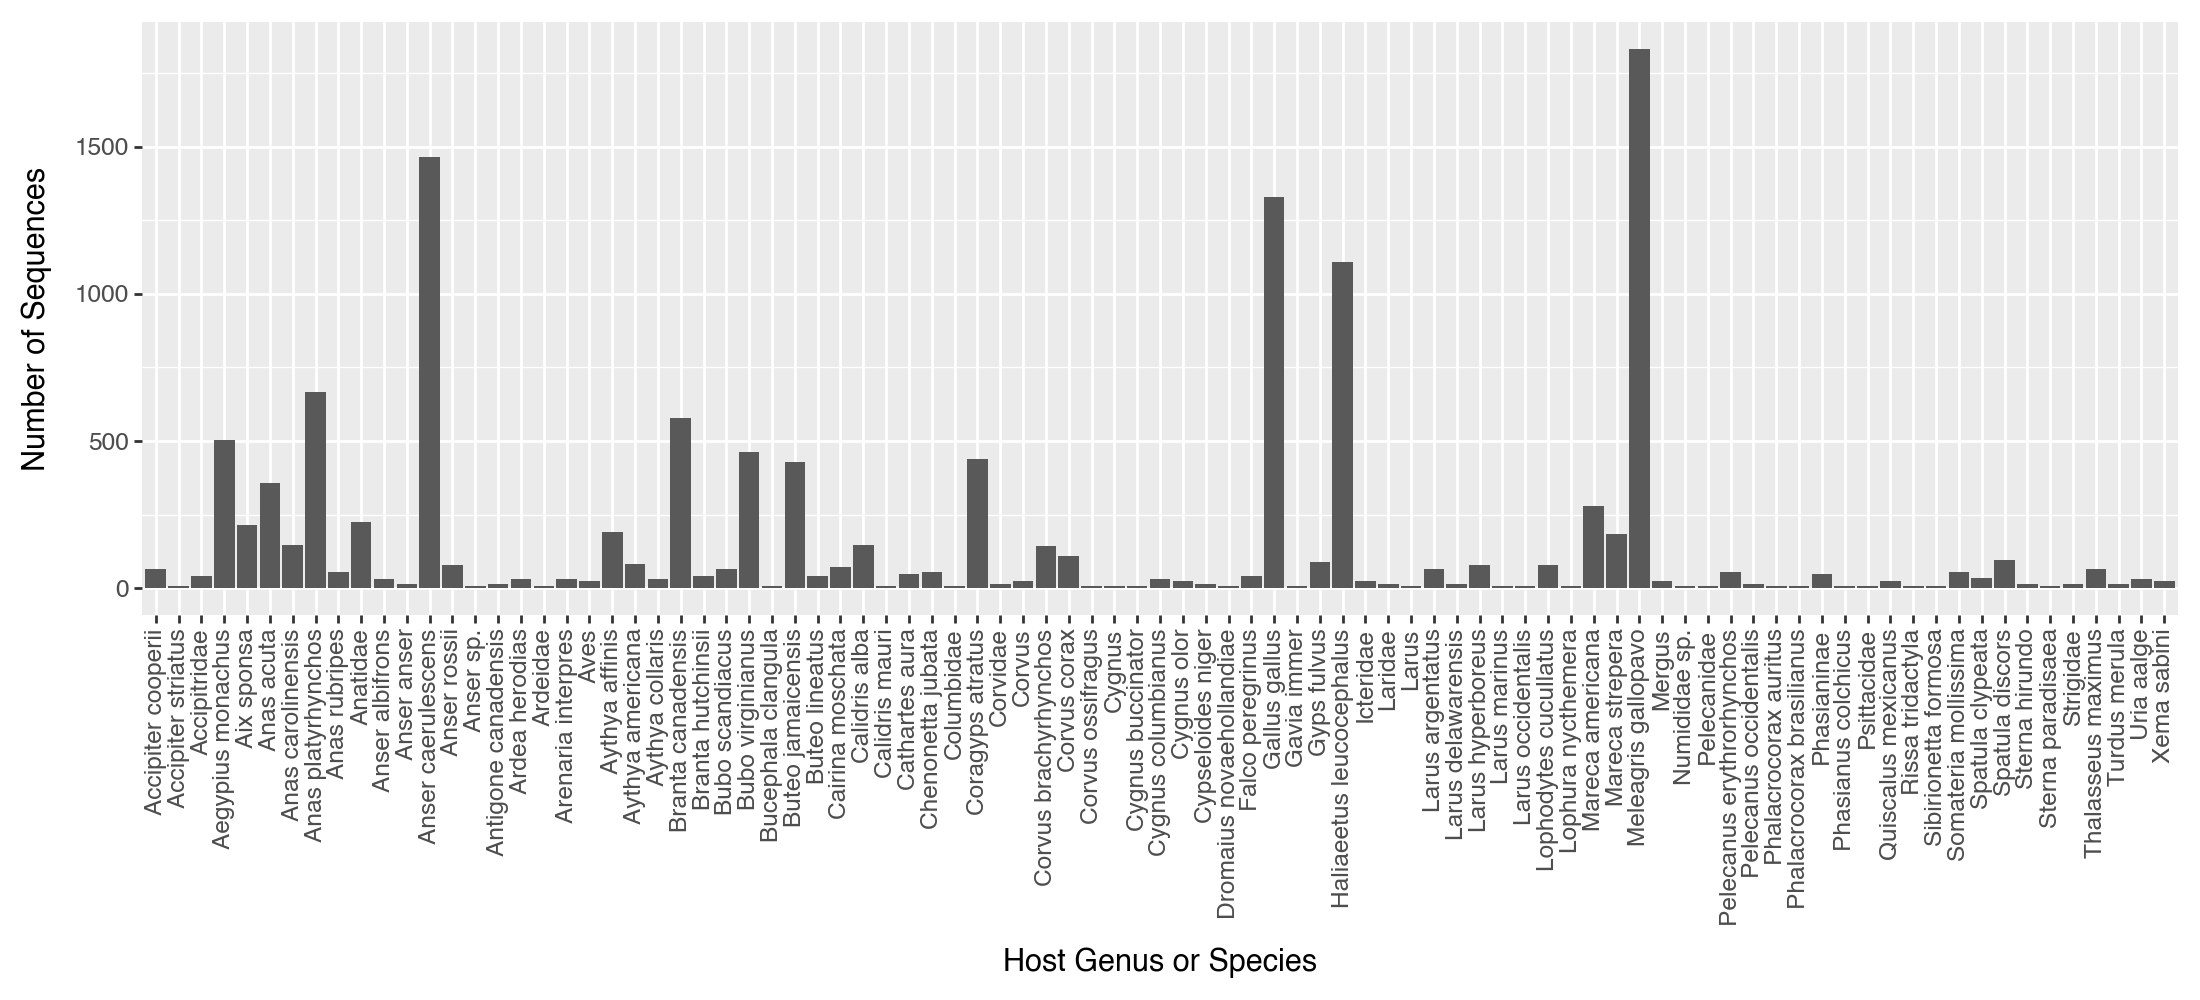

In [71]:
# To determine which bird orders are included in the metadata, first determine which bird species are in the metadata
included_avian_hosts = metadata_filtered["Host"].value_counts()
print(len(included_avian_hosts)) # So far, length is 89 species/genera/etc., but always check to see if that number changes

#included_avian_hosts.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/included_avian_hosts.csv", sep=",")

# Now make a plot of the included avian hosts
included_avian_hosts = included_avian_hosts.rename_axis("Host").reset_index()
included_avian_hosts = included_avian_hosts.sort_values(by = "count", ascending = False)
included_avian_hosts.head()

# plot this using ggplot
(
    ggplot(included_avian_hosts, aes(x = "Host", y = "count"))
    + geom_col()
    + labs(x = "Host Genus or Species", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 90))
    + theme(figure_size=(11,5))
)

In [72]:
# The following are a number of dictionaries necessary for mapping onto the metadata

State_Latitude_Dict = {"Alabama":32.7784,
                       "Alaska":64.0610,
                       "Arizona":34.2740,
                       "Arkansas":34.8938,
                       "California":37.1992,
                       "Colorado":38.9979,
                       "Connecticut":41.6220,
                       "Delaware":38.9895,
                       "Florida":28.6282,
                       "Georgia":32.6405,
                       "Hawaii":20.2951, 
                       "Idaho":44.3538,
                       "Illinois":40.0411,
                       "Indiana":39.8938,
                       "Iowa":42.0753,
                       "Kansas":38.4949,
                       "Kentucky":37.5360,
                       "Louisiana":31.0689,
                       "Maine":45.3702,
                       "Maryland":39.0550,
                       "Massachusetts":42.2596,
                       "Michigan":44.3461,
                       "Minnesota":46.2810,
                       "Mississippi":32.7351,
                       "Missouri":38.3568,
                       "Montana":47.0527,
                       "Nebraska":41.5392,
                       "Nevada":39.3306,
                       "New Hampshire":43.6805,
                       "New Jersey":40.1907,
                       "New Mexico":34.4066,
                       "New York":42.9543,
                       "North Carolina":35.5579,
                       "North Dakota":47.4499,
                       "Ohio":40.2863,
                       "Oklahoma":35.5910,
                       "Oregon":43.9336,
                       "Pennsylvania":40.8786,
                       "Rhode Island":41.6762,
                       "South Carolina":33.9169,
                       "South Dakota":44.4446,
                       "Tennessee":35.8605,
                       "Texas":31.4789,
                       "Utah":39.3057,
                       "Vermont":44.0688,
                       "Virginia":37.5229,
                       "Washington":47.3822,
                       "West Virginia":38.6409,
                       "Wisconsin":44.6243,
                       "Wyoming":42.9959}

State_Longitude_Dict = {"Alabama":-86.8290,
                       "Alaska":-152.2307,
                       "Arizona":-111.6582,
                       "Arkansas":-92.4429,
                       "California":-119.4505,
                       "Colorado":-105.5495,
                       "Connecticut":-72.7272,
                       "Delaware":-75.5051,
                       "Florida":-82.4426,
                       "Georgia":-83.4418,
                       "Hawaii":-156.3720, 
                       "Idaho":-114.6086,
                       "Illinois":-89.1965,
                       "Indiana":-86.2818,
                       "Iowa":-93.4959,
                       "Kansas":-98.3801,
                       "Kentucky":-85.3021,
                       "Louisiana":-91.9952,
                       "Maine":-69.2438,
                       "Maryland":-76.7909,
                       "Massachusetts":-71.8083,
                       "Michigan":-85.4114,
                       "Minnesota":-94.3046,
                       "Mississippi":-89.6680,
                       "Missouri":-92.4571,
                       "Montana":-109.645,
                       "Nebraska":-99.7968,
                       "Nevada":-116.6268,
                       "New Hampshire":-71.5818,
                       "New Jersey":-74.6733,
                       "New Mexico":-106.1128,
                       "New York":-75.5262,
                       "North Carolina":-79.3856,
                       "North Dakota":-100.4674,
                       "Ohio":-82.7938,
                       "Oklahoma":-97.4943,
                       "Oregon":-120.5617,
                       "Pennsylvania":-77.7985,
                       "Rhode Island":-71.5562,
                       "South Carolina":-80.8957,
                       "South Dakota":-100.2282,
                       "Tennessee":-86.3504,
                       "Texas":-99.3287,
                       "Utah":-111.6685,
                       "Vermont":-72.6663,
                       "Virginia":-78.8531,
                       "Washington":-120.4505,
                       "West Virginia":-80.6230,
                       "Wisconsin":-89.9941,
                       "Wyoming":-107.5527}

In [73]:
def check_duplicates(df):
    df["strain"] = df["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
    df["strain"] = df["strain"].str.lower()
    df["strain"] = df["strain"].str.replace("-", "")
    return print(df["strain"].is_unique)

# def format_date(datestr):
#     i = str(datestr)
#     date_object = datetime.strptime(i, '%Y-%m-%d')
#     return (date_object)

In [86]:
# Get state from strain name

# Make strain column
metadata_filtered.pipe(check_duplicates)

# Extract state from strain name
strain_split = metadata_filtered["strain"].str.split(pat = "/", expand = True)
#print(strain_split)

# Add State to metadata_filtered
metadata_filtered["State"] = strain_split[2]
#metadata_filtered.head()

False


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

In [87]:
# Separate country and state 

# Geo_Country and Geo_State columns (to put the State data in its own column)
split = metadata_filtered["Geo_Location"].str.split(pat = ':', expand = True)
metadata_filtered["Geo_Country"] = split[0]
metadata_filtered["Geo_State"] = split[1]
metadata_filtered["Geo_State"] = metadata_filtered["Geo_State"].str.strip()

# Change OH and Maricopa County to correct states
metadata_filtered["Geo_State"] = metadata_filtered["Geo_State"].replace(to_replace = ("OH", "Maricopa County, AZ"), value = ("Ohio", "Arizona"))

#metadata_USA = metadata_filtered[metadata_filtered["Country"] == "USA"]
print(set(metadata_filtered["Geo_State"]))

In [88]:
# Just to check in at this point:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: metadata_filtered
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: metadata_filtered
# I have added separate Geo_Country (should match Country column) and Geo_State columns: metadata_filtered

In [15]:
# Add columns for flyways

# Upload flyways dataframe
flyways = pd.read_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/flywayregions.csv", sep = ",", dtype={'location':str})
column_mapper = {"location":"Geo_State"}
flyways = flyways.rename(mapper = column_mapper, axis = 1)

# Add Mexican states to flyways dataframe
mexico_flyways = pd.DataFrame({"Geo_State":["EdoMex,Temascalapa", "Sonora", "Puebla,libres", "Guanajuato", "Puebla,Tehuitzingo", "EdoMex,texcoco"],
        "flyway":["Central Flyway", "Pacific Flyway", "Central Flyway", "Central Flyway", "Central Flyway", "Central Flyway"],
        "geo_region_na":["Mexico", "Mexico", "Mexico", "Mexico", "Mexico", "Mexico"]
       })
flyways_updt = flyways._append(mexico_flyways, ignore_index = True)

# Add flyways to metadata

metadata_filtered_flyways = pd.merge(metadata_filtered, flyways_updt, on = "Geo_State", how = "outer")
#metadata_filtered_flyways.head()
print(len(metadata_filtered_flyways)) 
# When added how="outer" to the merge, now have 12,895 of 13,327 rows and state-less sequences are still included
metadata_filtered_flyways.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_flyways.csv", sep=",")

12895


In [16]:
# If I want to limit to just US states, I can use the following code

#states_to_keep = set(metadata_USA["Geo_State"])
#US_flyways = flyways[flyways["Geo_State"].isin(states_to_keep)]
#non_US_flyways = set(flyways["Geo_State"])-states_to_keep

In [17]:
# Add columns for host bird order

birdies = pd.read_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/included_avian_hosts.csv", sep = ",")

metadata_filtered_flyways_birdies = pd.merge(metadata_filtered_flyways, birdies, on="Host")
print(len(metadata_filtered_flyways_birdies)) #Length of this is 12,870 (missing 25 rows from previous)
#metadata_filtered_flyways_birdies.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/metadata_filtered_flyways_birdies.csv", sep=",")

12870


In [18]:
# Add columns for latitide and longitude

metadata_filtered_flyways_birdies["State_Lat"] = metadata_filtered_flyways_birdies["Geo_State"].map(State_Latitude_Dict)
metadata_filtered_flyways_birdies["State_Long"] = metadata_filtered_flyways_birdies["Geo_State"].map(State_Longitude_Dict)
metadata_filtered_flyways_birdies["Centroid_Coord"] = metadata_filtered_flyways_birdies["State_Lat"].astype(str) + ',' + metadata_filtered_flyways_birdies["State_Long"].astype(str)

In [19]:
#list(metadata_filtered_flyways_birdies.columns)

In [20]:
# Drop all the excess columns you made

drop_columns = ["count", "commonname", "broad", "notes", "geo_region_na", "Geo_Location", "State_Lat", "State_Long"]
metadata_datetime_bird_flyway_coord = metadata_filtered_flyways_birdies.drop(labels=drop_columns, axis = 1)
metadata_datetime_bird_flyway_coord.head()

,Accession,Organism_Name,SRA_Accession,Organization,Org_location,Release_Date,Isolate,Species,Molecule_type,Length,...,BioSample,BioProject,GenBank_Title,Collection_datetime,Geo_Country,Geo_State,flyway,order,domesticstatus,Centroid_Coord
0,OQ957841.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2280.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,USA,Alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
1,OQ957842.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2274.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,USA,Alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
2,OQ957843.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),2151.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,USA,Alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
3,OQ957844.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),1704.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,USA,Alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"
4,OQ957845.1,Influenza A virus,NaN,"United States Department of Agriculture, Agric...",USA,2023-08-23,22-004941-003,Alphainfluenzavirus influenzae,ssRNA(-),1497.0,...,NaN,NaN,Influenza A virus (A/American Wigeon/Alabama/2...,2022-02-05,USA,Alabama,Mississippi Flyway,anseriformes,wild,"32.7784,-86.829"


In [21]:
# Another check in:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: metadata_filtered
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: metadata_filtered
# I have added separate Geo_Country (should match Country column) and Geo_State columns: metadata_filtered
# I have filtered for just sequences from the USA: metadata_USA
# I have addded the corresponding flyway data
# I have added the corresponding host (bird) taxonomic order and domestic status
# I have added the corresponding latitude and longitude

In [50]:
#metadata_datetime_bird_USflyway_coord.to_csv("/Users/Desktop/Moncla_Lab/H5_avian_ecology/metadata/updated_metadata_07012024.csv", sep = ',')
metadata_datetime_bird_flyway_coord.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/updated_metadata_07012024.tsv", sep = '\t')

In [59]:
# Because each isolate has multiple segments, we want to split the big metadata file into separate files by segment

segment1_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 1] # Encodes PB2 
segment2_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 2] # Encodes PB1 and sometimes PB1-F2
segment3_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 3] # Encodes PA
segment4_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 4] # Encodes HA
segment5_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 5] # Encodes NP
segment6_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 6] # Encodes NA
segment7_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 7] # Encodes M1 matrix
segment8_metadata = metadata_datetime_bird_flyway_coord[metadata_datetime_bird_flyway_coord["Segment"] == 8] # Encodes NS1, NEP, and NS2

print(len(segment1_metadata))
#segment1_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment1_metadata_07012024.csv", sep=',')
print(len(segment2_metadata))
#segment2_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment2_metadata_07012024.csv", sep=',')
print(len(segment3_metadata))
#segment3_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment3_metadata_07012024.csv", sep=',')
print(len(segment4_metadata))
#segment4_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment4_metadata_07012024.csv", sep=',')
print(len(segment5_metadata))
#segment5_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment5_metadata_07012024.csv", sep=',')
print(len(segment6_metadata))
#segment6_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment6_metadata_07012024.csv", sep=',')
print(len(segment7_metadata))
#segment7_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment7_metadata_07012024.csv", sep=',')
print(len(segment8_metadata))
#segment8_metadata.to_csv("/Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/segment8_metadata_07012024.csv", sep=',')
# adds up to 12,870 (good!)

1585
1592
1599
1621
1617
1618
1618
1620


/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_count : Removed 4004 rows containing non-finite values.


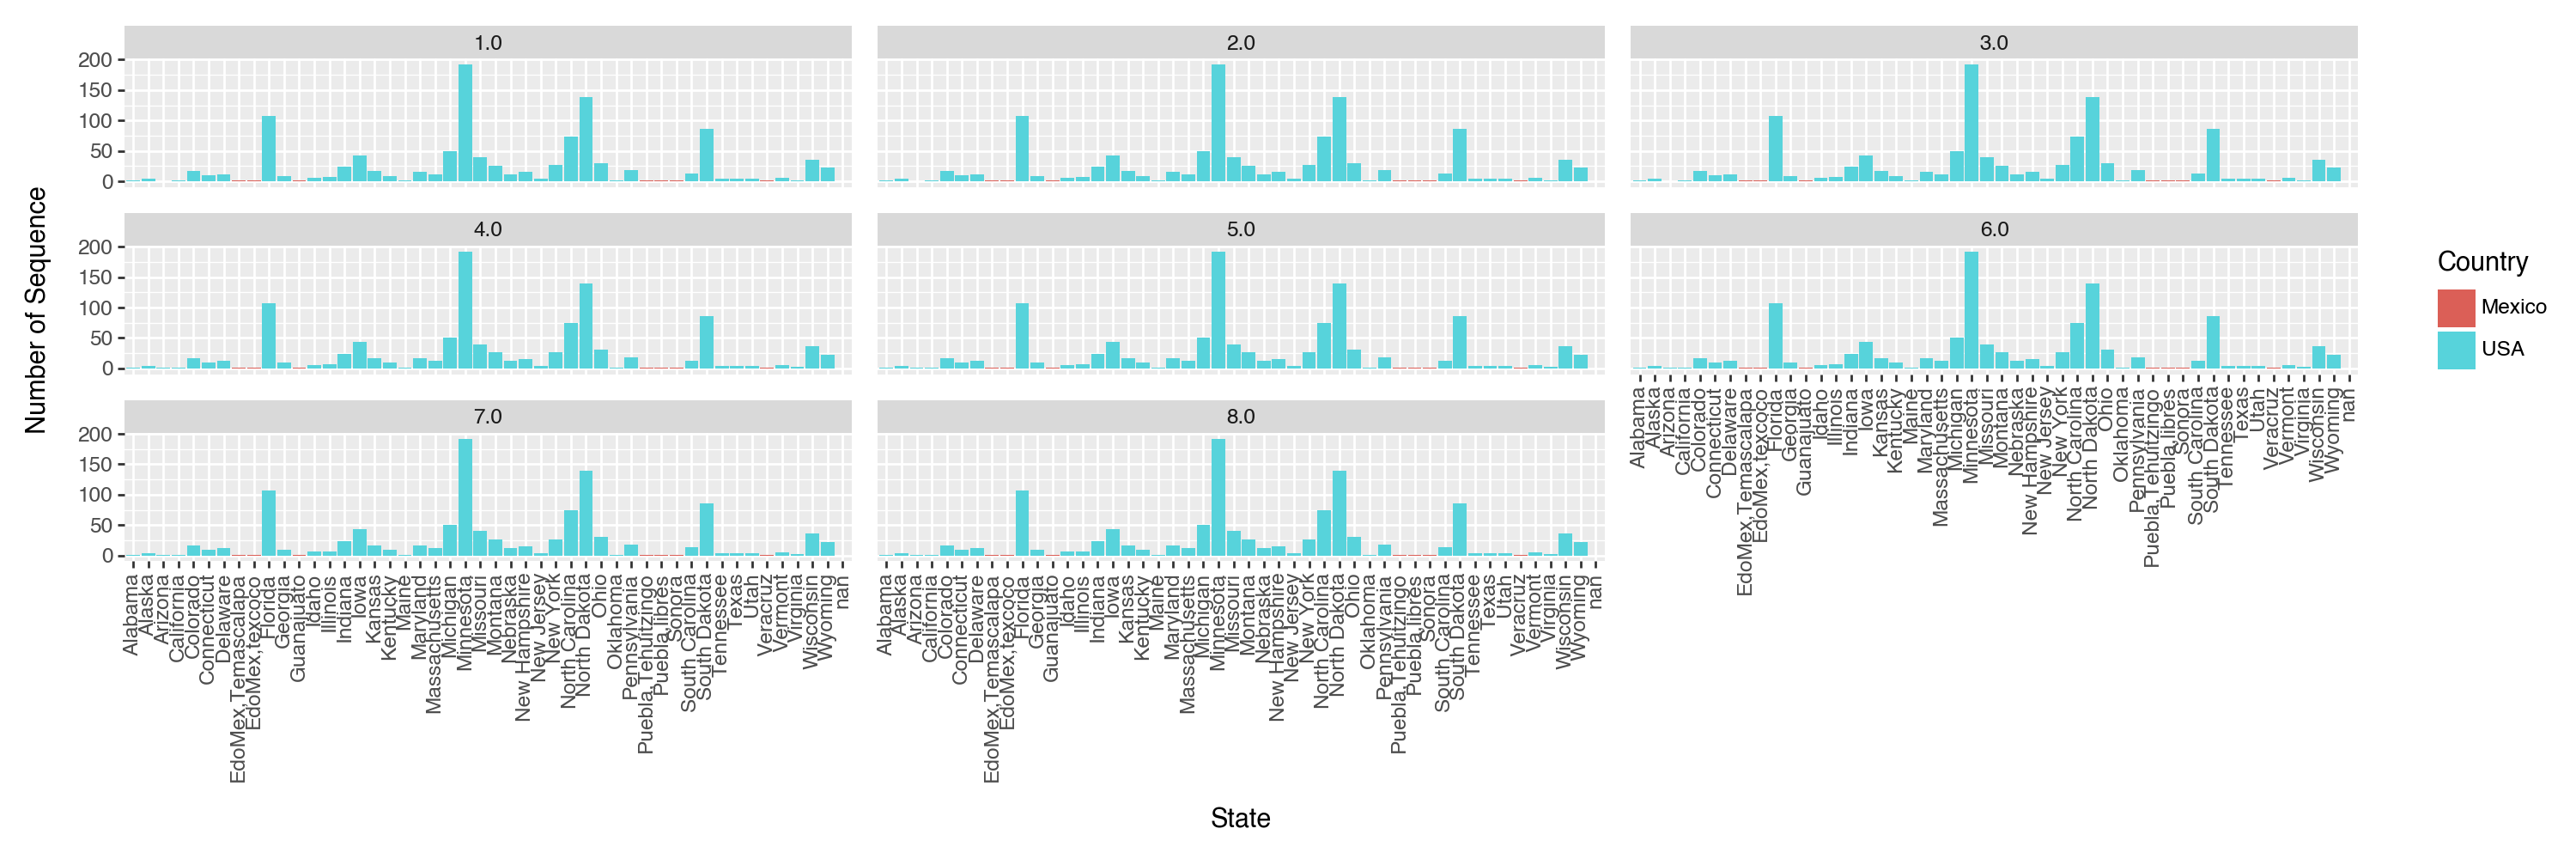

In [22]:
# The following script investigates how many sequences have state-level collection location data

# Make a dataframe of the number of sequences from each state 
metadata_states = pd.DataFrame(metadata_datetime_bird_flyway_coord["Geo_State"].value_counts())
metadata_states = metadata_states.rename_axis("State").reset_index()
#print(metadata_states)

# Plot this data using ggplot
# (
# ggplot(metadata_states, aes(x = "State", y = "count")) 
#     + geom_col()
#     + labs(x = "State", y = "Number of Sequences")
#     #+ axis_text_x(element_text(rotation = "vertical"))
#     #+ element_text(axis_text_x(rotation = "vertical"))
#     + theme(axis_text_x = element_text(rotation = 90))
# )

# Plot sequences by state, facetted by segment
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Geo_State", fill = "Country"))
    + geom_bar(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "State", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 5))
)

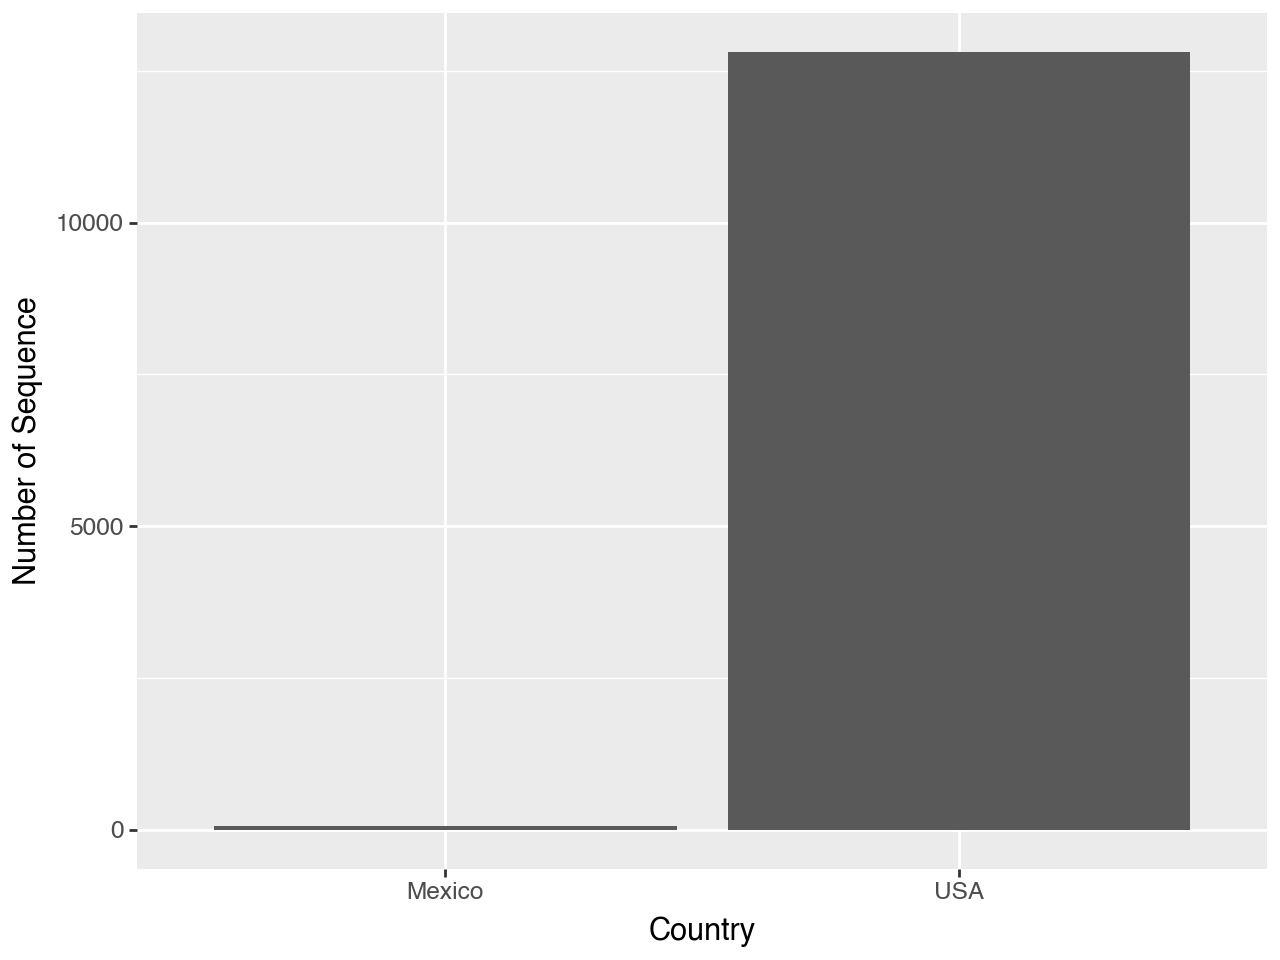

In [25]:
# Plot sequences state, facetted by country, because I'm curious
# (
#     ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Geo_State", fill = "Country"))
#     + geom_bar(stat = "count")
#     + facet_wrap("Country")
#     + labs(x = "State", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (13, 5))
# )

# Or just by country, either one
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Country"))
    + geom_bar(stat = "count")
    + labs(x = "Country", y = "Number of Sequence")
#    + theme(axis_text_x = element_text(rotation = 90), figure_size = (13, 5))
)

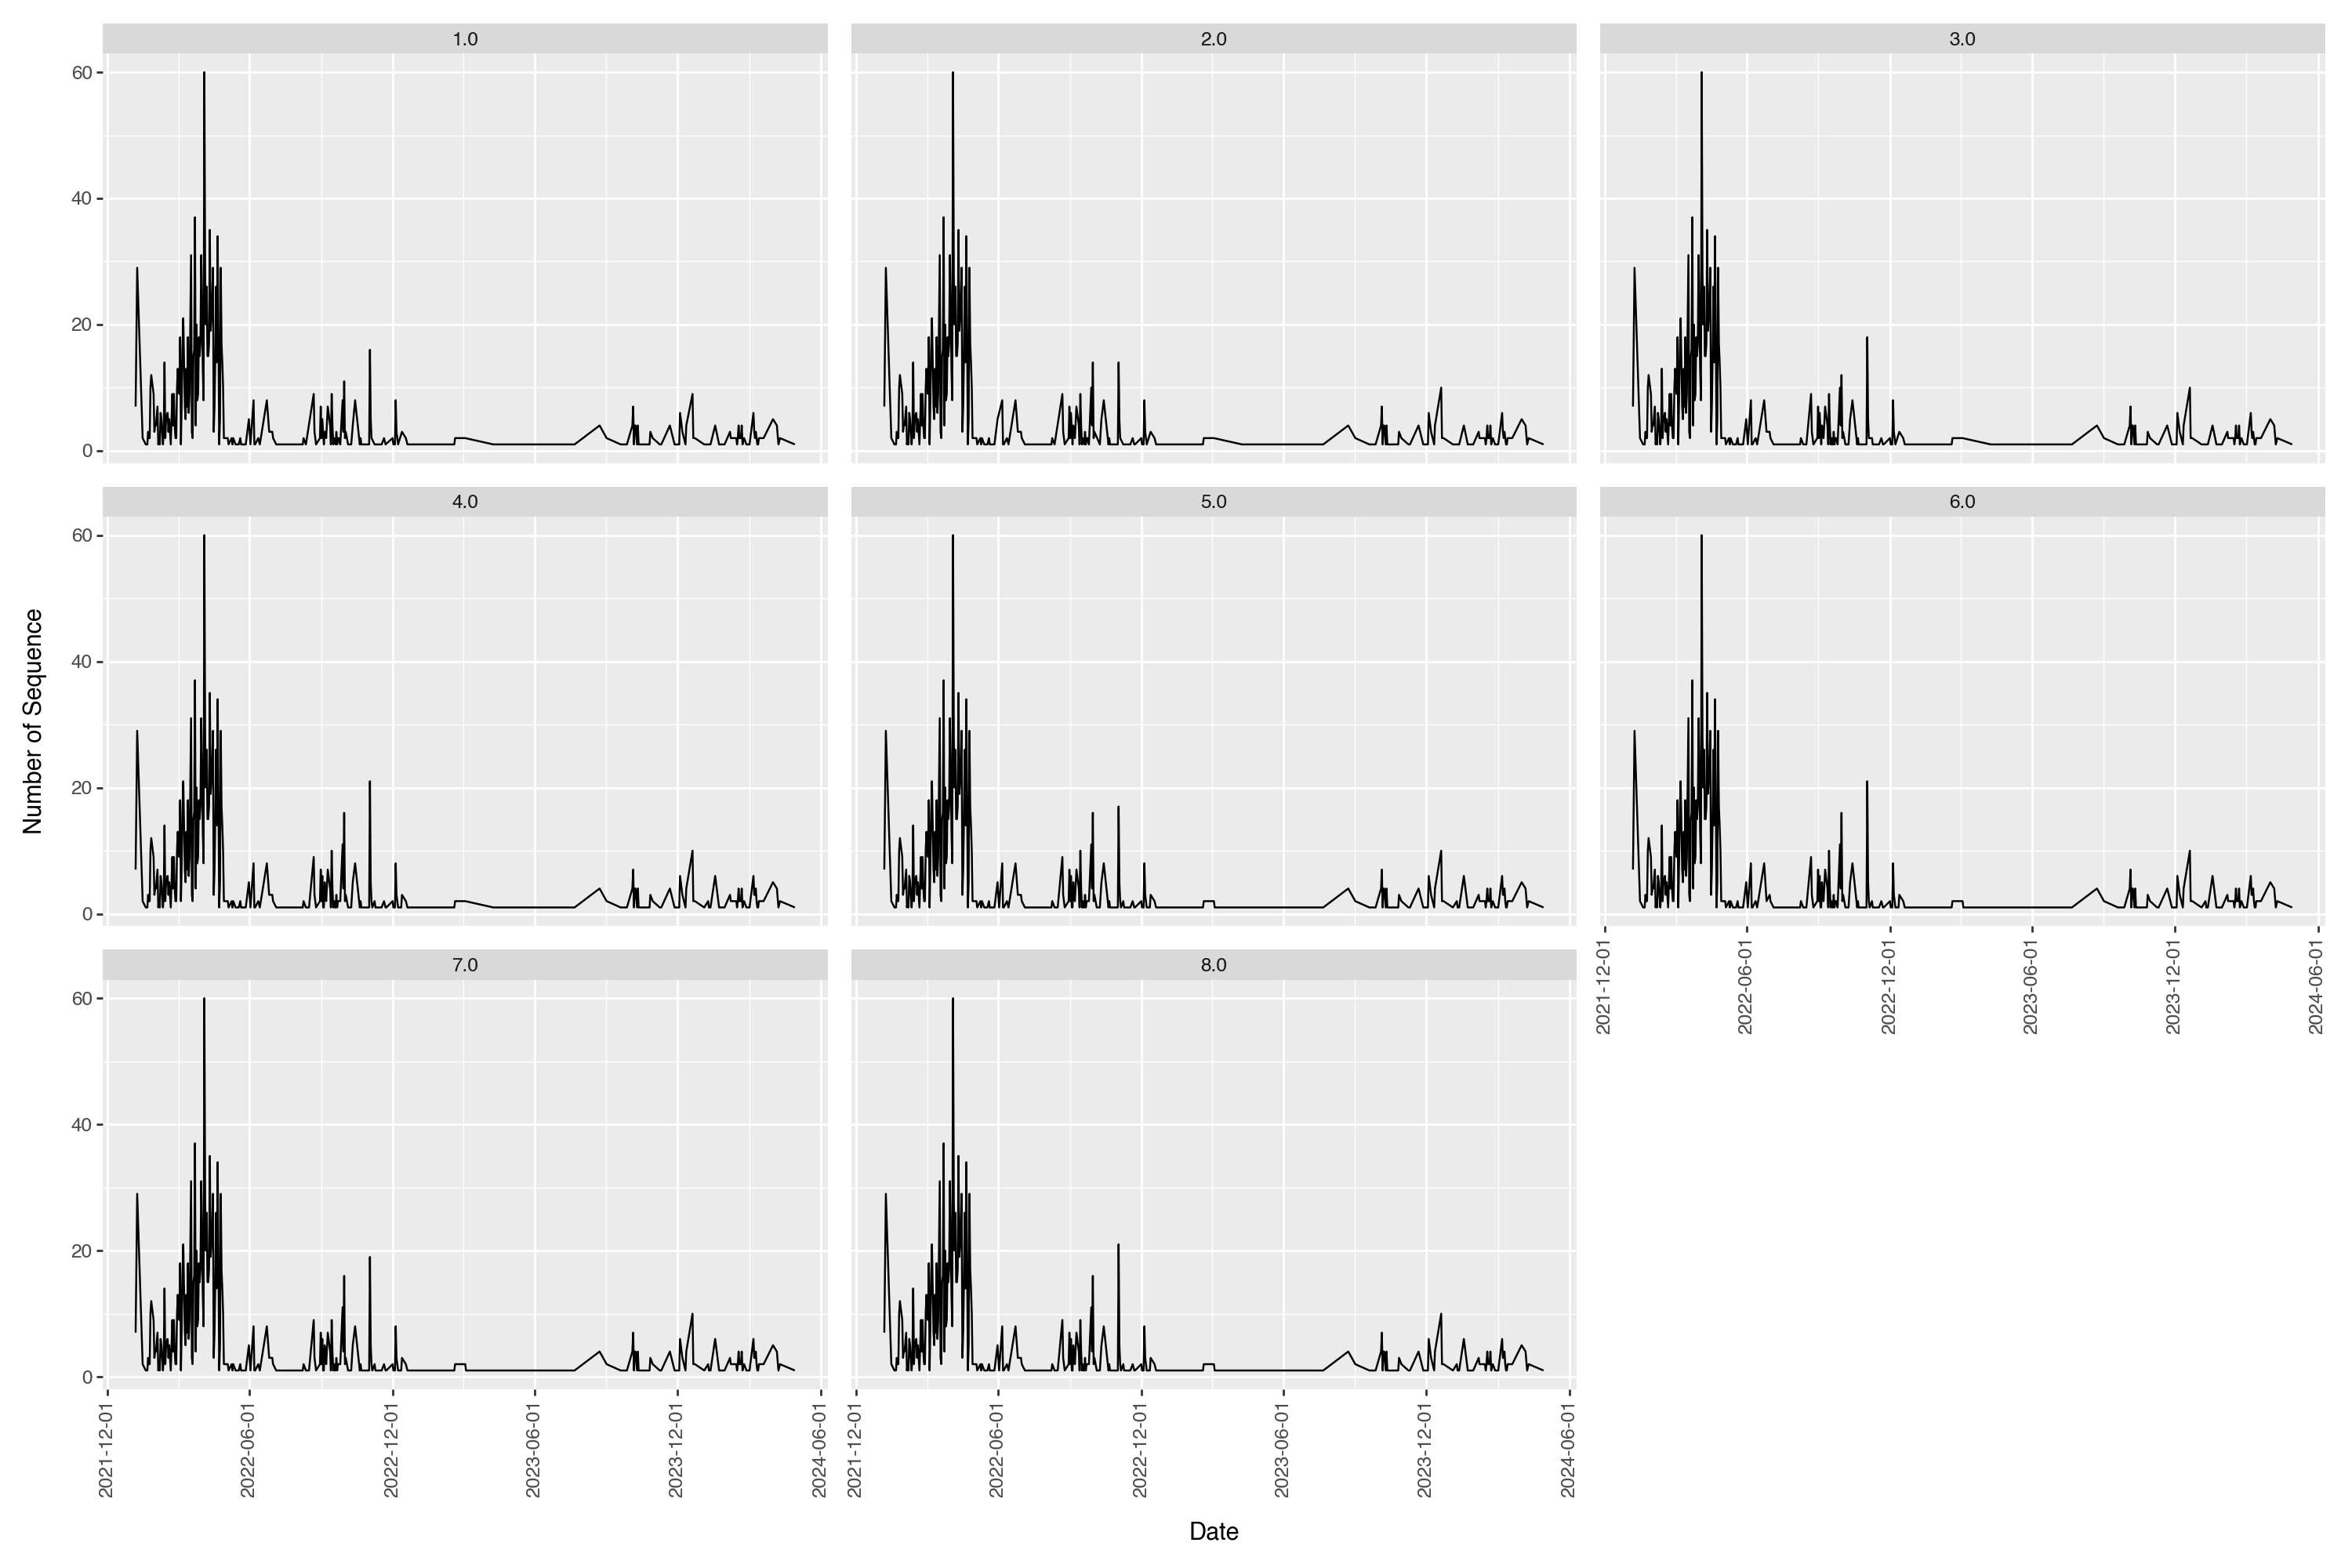

In [23]:
# Plot the number of sequences by date
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime"))
    + geom_line(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

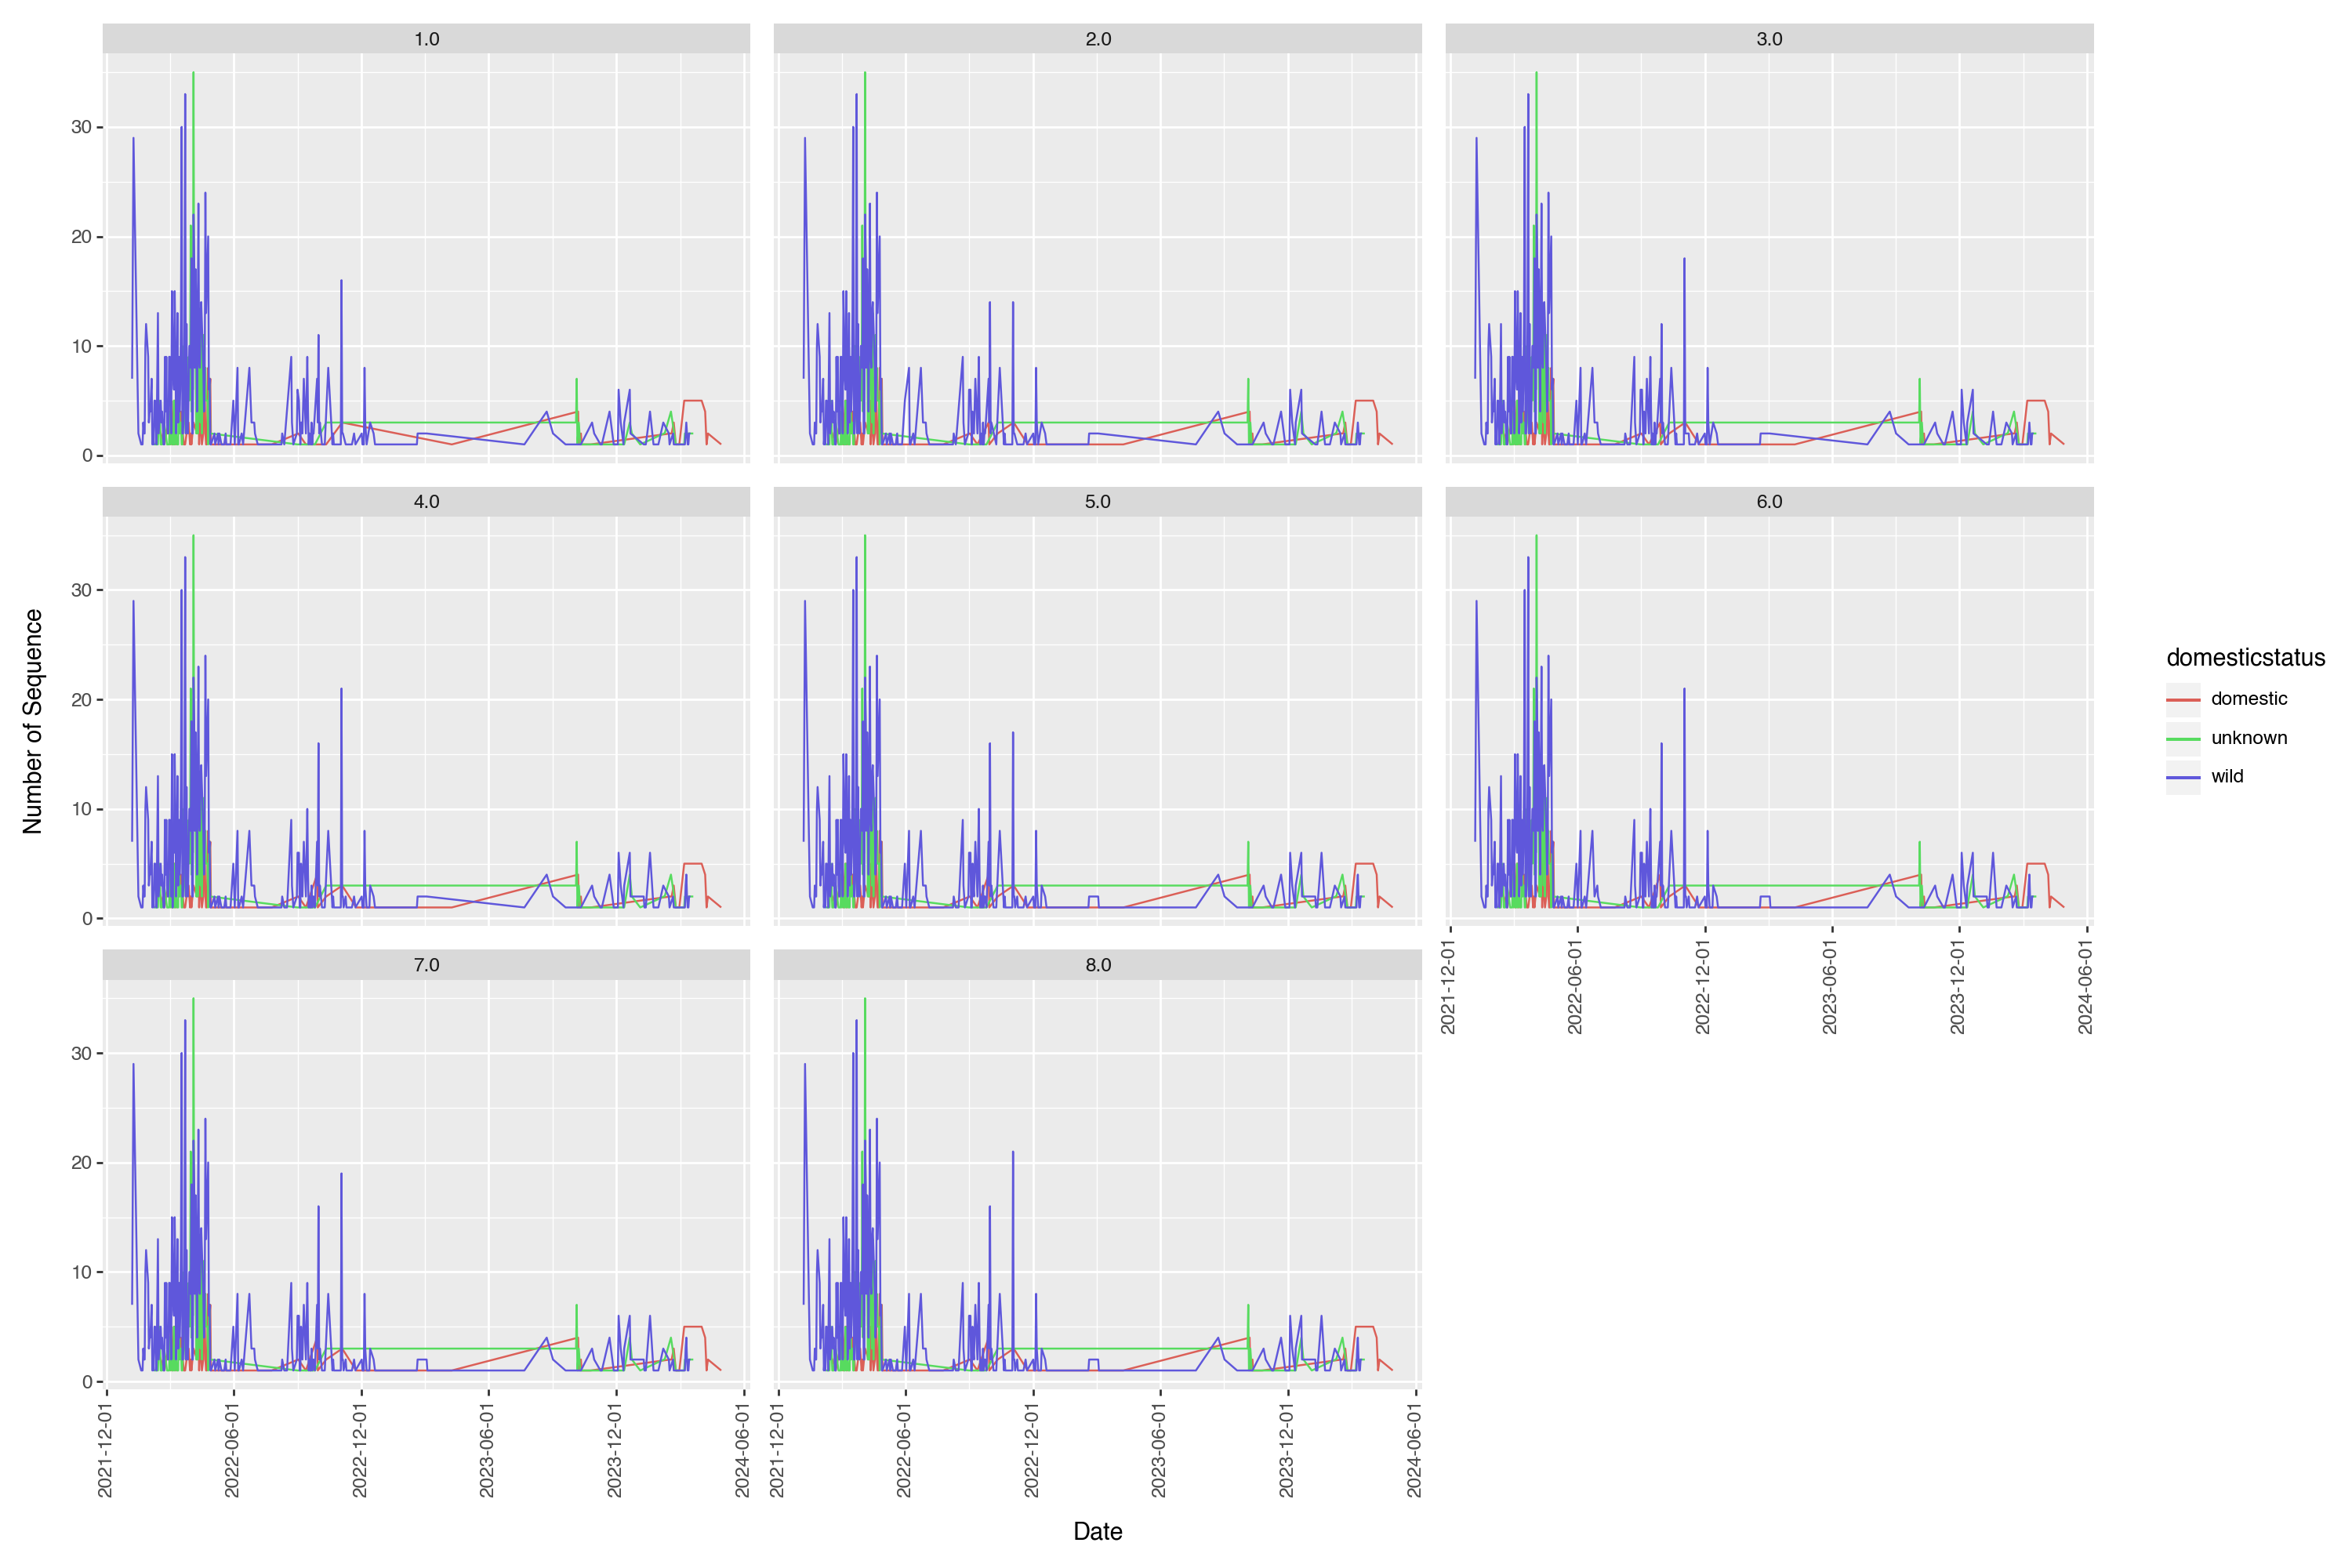

In [24]:
# Plot Sequences over time, with one line for wild birds and one line for domestic birds, facetted by segment
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", color = "domesticstatus"))
    + geom_line(stat = "count")
    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

In [89]:
# How many sequences per flyway
metadata_datetime_bird_flyway_coord["flyway"].value_counts()

flyway
Mississippi Flyway    3493
Central Flyway        2632
Atlantic Flyway       2600
Pacific Flyway         133
Name: count, dtype: int64

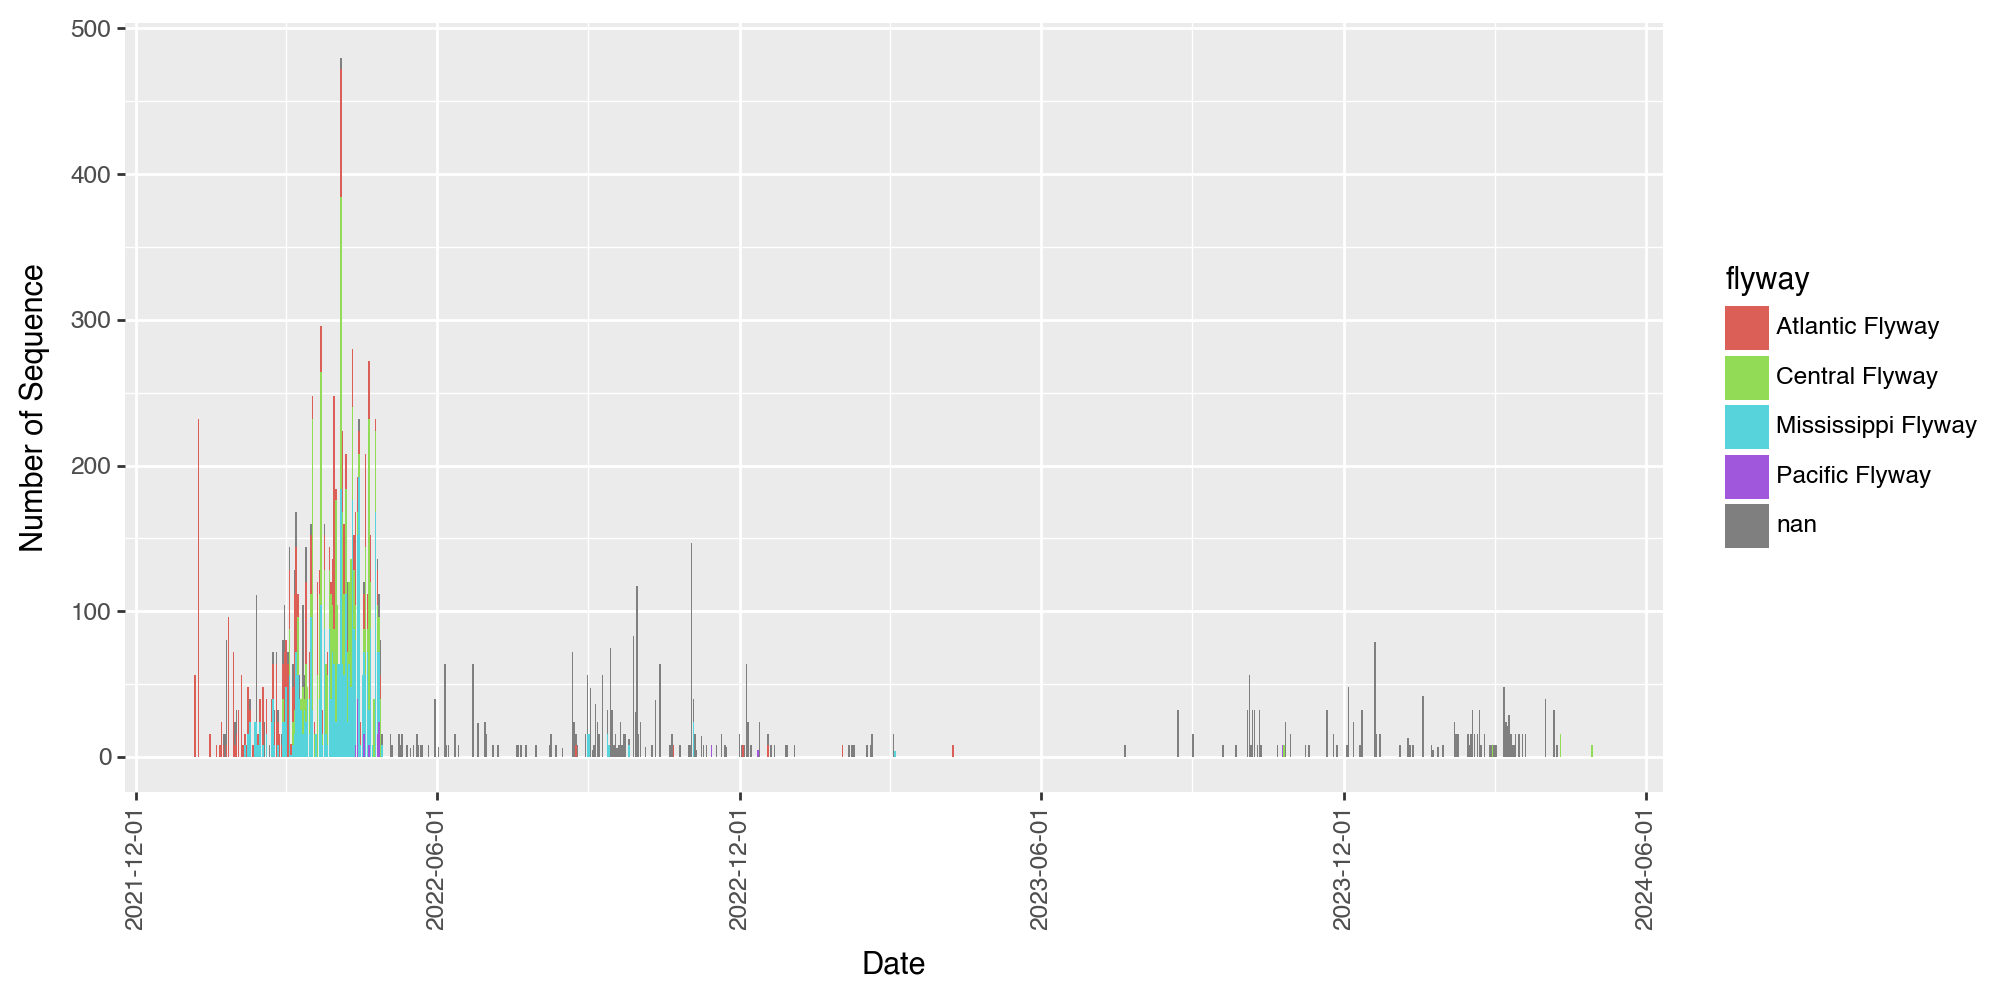

In [37]:
# Plot sequences over time, by flyway
# (
#     ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", color = "flyway"))
#     + geom_line(stat = "count")
# #    + facet_wrap("Segment")
#     + labs(x = "Date", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
# )

# I don't love this as a line graph... what about as a bar graph
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", fill = "flyway"))
    + geom_bar(stat = "count", size = 10)
#    + facet_wrap("Segment")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
)

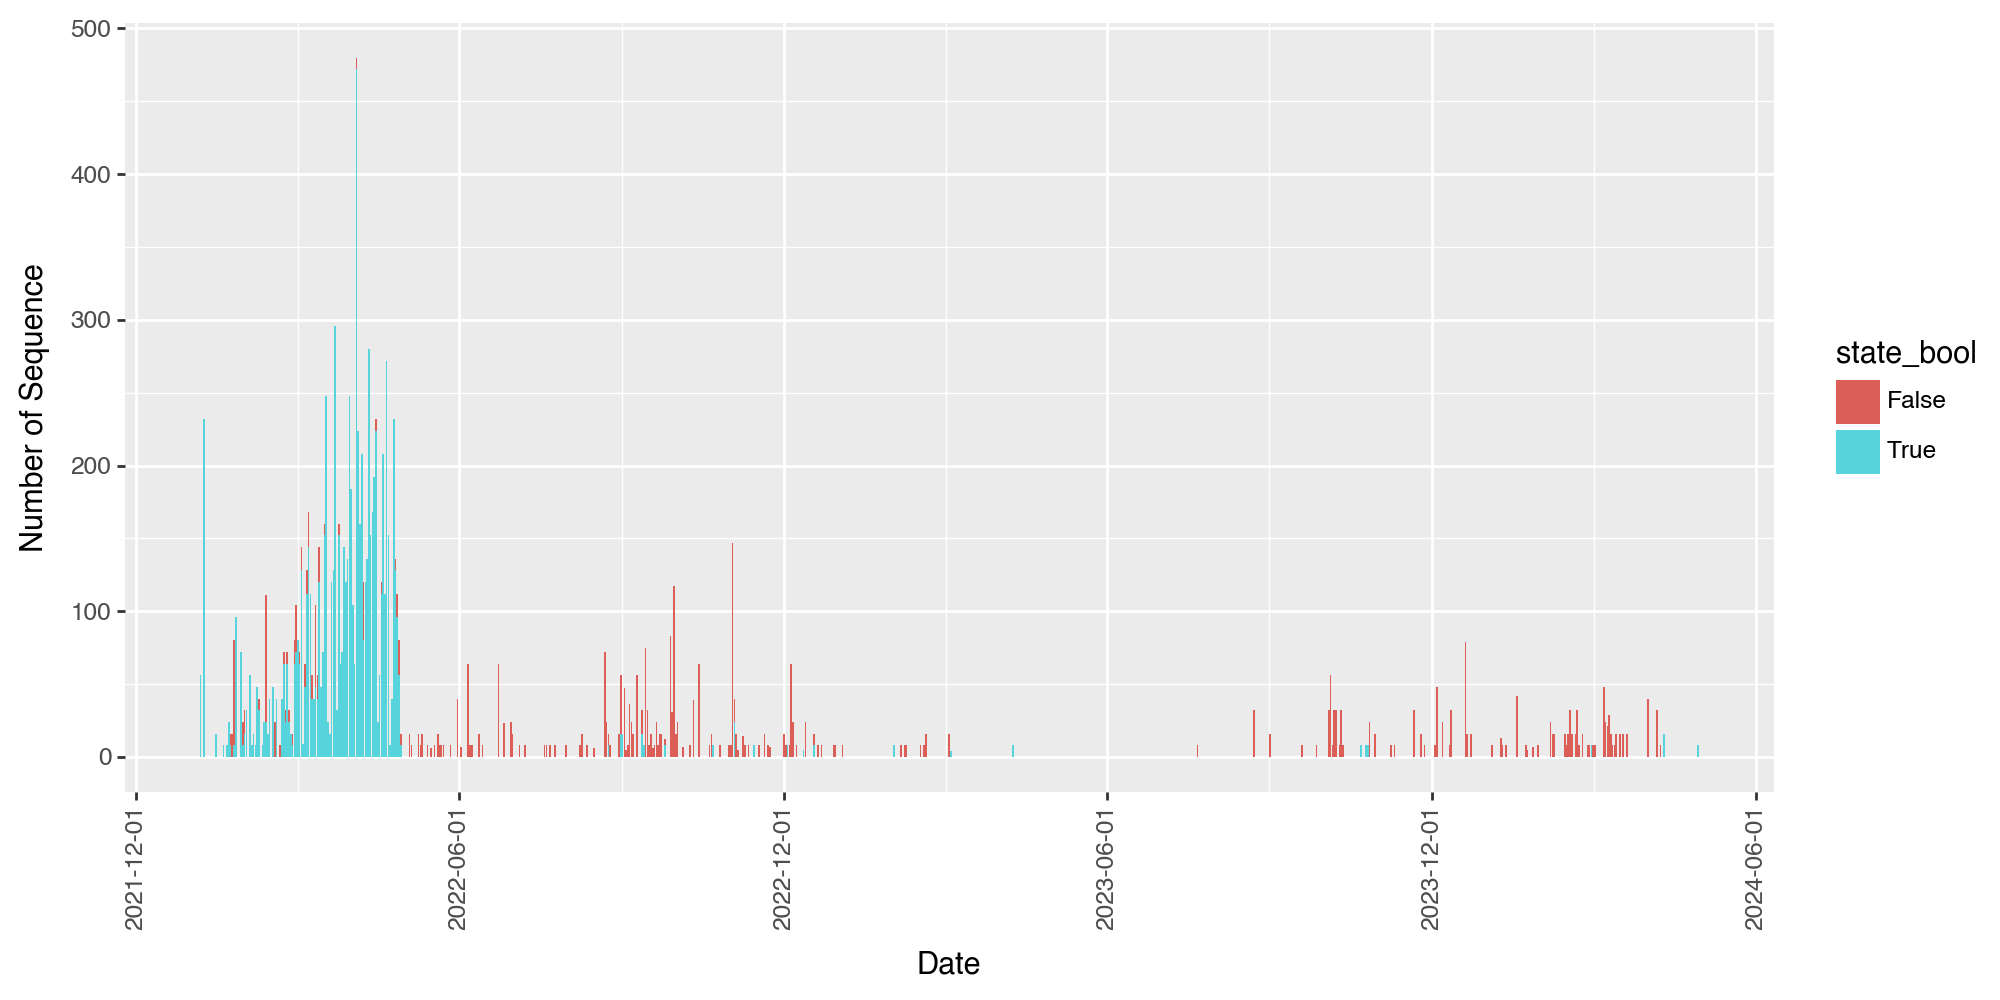

In [43]:
# Why are we losing flyway data after the first 6 mo? Is it because we're loosing state data

# New column if there is a state or not
metadata_datetime_bird_flyway_coord["state_bool"] = metadata_datetime_bird_flyway_coord["Geo_State"].apply(lambda x: bool(x) if pd.notna(x) else False)
#print(metadata_datetime_bird_flyway_coord["state_bool"])

# Plot
(
    ggplot(metadata_datetime_bird_flyway_coord, aes(x = "Collection_datetime", fill = "state_bool"))
    + geom_bar(stat = "count")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
)

In [76]:
metadata_datetime_bird_flyway_coord.pipe(check_duplicates)
# not working because you need to use .apply on a Series (but can use .pipe on a df)

False


In [61]:
segment1_metadata.pipe(check_duplicates)
#print(segment1_metadata.columns)

False
Index(['Accession', 'Organism_Name', 'SRA_Accession', 'Organization',
       'Org_location', 'Release_Date', 'Isolate', 'Species', 'Molecule_type',
       'Length', 'Sequence_Type', 'Nuc_Completeness', 'Genotype', 'Segment',
       'Country', 'USA', 'Host', 'Isolation_Source', 'Collection_Date',
       'BioSample', 'BioProject', 'GenBank_Title', 'Collection_datetime',
       'Geo_Country', 'Geo_State', 'flyway', 'order', 'domesticstatus',
       'Centroid_Coord', 'Month', 'state_bool', 'strain'],
      dtype='object')


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_41251/2926143913.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

In [47]:
# Toying with pulling out strain name here

# Step 1: pull out the strain name and make it a new column
#strain_name = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
#print(metadata_datetime_bird_flyway_coord["strain"])
#strain_bool = metadata_datetime_bird_flyway_coord["GenBank_Title"].str.contains("A[\/].*[\/]\d{4}\(H5N\w\)", case = True, flags = 0, regex = True)

# Step 2: remove all uppercases, dashes, hyphens
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["strain"].str.lower()
metadata_datetime_bird_flyway_coord["strain"] = metadata_datetime_bird_flyway_coord["strain"].str.replace("-", "")

# Step 3: check if there are any duplicates within each segment file
metadata_datetime_bird_flyway_coord["strain"].is_unique

# Now I have to make this into a function

False

In [ ]:
# infile = updated_metadata_07012024.csv # or as TSV, depending on how you save it
# strain_dict = {}
# for line in infile:
#     strain_name = 
#     if strain in strain_dict
#     else:
#         strain_dict[strain_name] = {}